<a href="https://colab.research.google.com/github/Oumohgh/ChestScan_AI-/blob/main/Brief_transfer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import les biblio

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import kagglehub
from google.colab import userdata
import tensorflow as tf
import os
import pprint as pp
from PIL import Image, ImageOps
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
import random
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import layers, models
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve, ConfusionMatrixDisplay)

# EDA

In [ ]:
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print(path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
/kaggle/input/chest-xray-pneumonia


In [ ]:
!ls {path}/chest_xray/train/NORMAL | head -n 10

IM-0115-0001.jpeg
IM-0117-0001.jpeg
IM-0119-0001.jpeg
IM-0122-0001.jpeg
IM-0125-0001.jpeg
IM-0127-0001.jpeg
IM-0128-0001.jpeg
IM-0129-0001.jpeg
IM-0131-0001.jpeg
IM-0133-0001.jpeg


## Retrieval of raw images

In [ ]:

training_path = path + "/chest_xray/train"
testing_path = path + "/chest_xray/test"
validation_path = path + "/chest_xray/val"

In [ ]:
allowed_extensions = ("png", "jpg", "jpeg")
def get_images(new_path: str):
  dataset = tf.keras.preprocessing.image_dataset_from_directory(new_path, label_mode='binary', batch_size=None, color_mode="rgb", image_size=(180,180), crop_to_aspect_ratio=False, shuffle=True)



  return dataset


In [ ]:
# Dataframe with two columns image & label, image: Image refrence, label: normal || pneumonia
raw_training_images = get_images(training_path)
# pp.pprint(raw_training_images)


Found 5216 files belonging to 2 classes.


In [ ]:
def convert_to_panadas(dataset):
  ds_labels=[]
  for image, labels in dataset:
     ds_labels.append({"image": image.numpy(), "label": labels.numpy()[0]})
  new_df = pd.DataFrame.from_dict(ds_labels)
  return new_df


In [ ]:
raw_training_images = convert_to_panadas(raw_training_images)

In [ ]:
raw_testing_images = get_images(testing_path)

Found 624 files belonging to 2 classes.


In [ ]:
raw_testing_images = convert_to_panadas(raw_testing_images)

In [ ]:
raw_validation_images = get_images(validation_path)

Found 16 files belonging to 2 classes.


In [ ]:
raw_validation_images = convert_to_panadas(raw_validation_images)

## Data analysis

<Figure size 1000x1000 with 0 Axes>

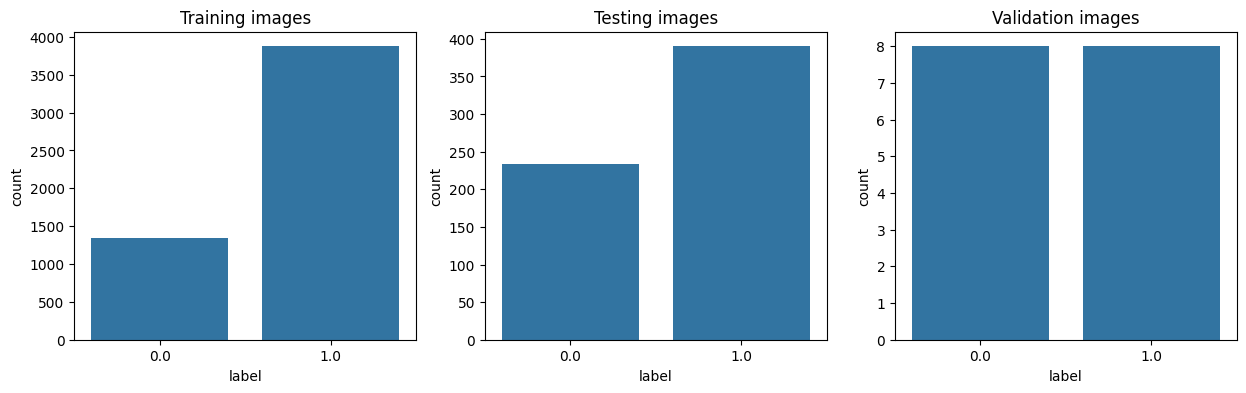

In [ ]:
plt.figure(figsize=(10, 10))
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4))

sns.countplot(x="label", data=raw_training_images, ax=axes[0])
axes[0].set_title("Training images")

sns.countplot(x="label", data=raw_testing_images, ax=axes[1])
axes[1].set_title("Testing images")

sns.countplot(x="label", data=raw_validation_images, ax=axes[2])
axes[2].set_title("Validation images")

plt.show()

In [ ]:
training_count = raw_training_images.groupby("label").count()
testing_count = raw_testing_images.groupby("label").count()
validation_count = raw_validation_images.groupby("label").count()

stats = {
    "training": {
        "total": len(raw_training_images),
        "normal_percentage": (training_count.loc[0, "image"] * 100) / len(raw_training_images),
        "pneumonia_percentage": (training_count.loc[1, "image"] * 100) / len(raw_training_images)
    },
    "testing": {
        "total": len(raw_testing_images),
        "normal_percentage": (testing_count.loc[0, "image"] * 100) / len(raw_testing_images),
        "pneumonia_percentage": (testing_count.loc[1, "image"] * 100) / len(raw_testing_images)
    },
    "validation": {
        "total": len(raw_validation_images),
        "normal_percentage": (validation_count.loc[0, "image"] * 100) / len(raw_validation_images),
        "pneumonia_percentage": (validation_count.loc[1, "image"] * 100) / len(raw_validation_images)
    }
}

stats_df = pd.DataFrame(stats)
stats_df

,training,testing,validation
total,5216.000000,624.0,16.0
normal_percentage,25.709356,37.5,50.0
pneumonia_percentage,74.290644,62.5,50.0


### Interpretation
The class seperation in the trainnig set is very drastice compared to the other two sets, this may result on an overfitted model, which we'll need to keep a close eye on, and verify proper fitting using the validation set.

## Image resizing & sanity check

In [ ]:



def scale_vector(vecotre):
  return vecotre / 255.0

### Documentation
Image data can get corrupted, so we use the image.verify sanity check.
Then we risze the image if not corrupted, to a 180x180 px, with the @cover method, while converting the color's to RGB values.

If the image failes the sanity check, the function returns None, which then will be dropped in the next step

In [ ]:
scaled_training_images = raw_training_images
scaled_training_images["image"] = scaled_training_images["image"].map(scale_vector)
scaled_training_images.dropna(inplace=True)

In [ ]:
scaled_testing_images = raw_testing_images.copy()
scaled_testing_images["image"] = scaled_testing_images["image"].map(scale_vector)
scaled_testing_images.dropna(inplace=True)

In [ ]:
scaled_validation_images = raw_validation_images
scaled_validation_images["image"] = scaled_validation_images["image"].map(scale_vector)
scaled_validation_images.dropna(inplace=True)

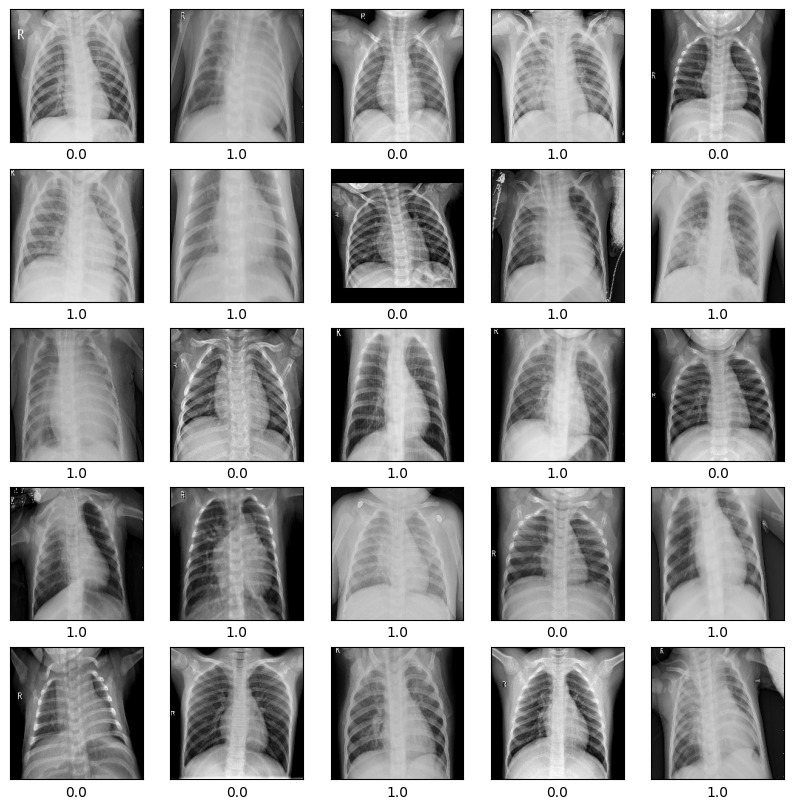

In [ ]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(scaled_training_images.iloc[i]["image"])
    plt.xlabel(scaled_training_images.iloc[i]['label'])
plt.show()

In [ ]:
def get_weights(df: pd.DataFrame):
  labels = df["label"].unique()
  weights = compute_class_weight(class_weight="balanced", classes=labels, y=df["label"])
  class_weights = dict(zip(labels, weights))
  return class_weights

# Modelisation

In [ ]:
model = models.Sequential([
    layers.Input(shape=(180, 180, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.Flatten(),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 215168)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │    13,770,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,864,129 (52.89 MB)

 Trainable params: 13,864,129 (52.89 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy", "precision", "recall", "auc"])

X_train = np.stack(scaled_training_images['image'].to_list()).astype("float32")
y_train = scaled_training_images['label'].to_numpy().astype("float32")

x_val = np.stack(scaled_validation_images['image'].to_list()).astype("float32")
y_val = scaled_validation_images['label'].to_numpy().astype("float32")

class_weights = {int(k): float(v) for k, v in get_weights(scaled_training_images).items()}

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_auc", mode="max", patience=5, restore_best_weights=True
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1
)

history = model.fit(
    X_train, y_train,
    batch_size=64,
    epochs=10,
    class_weight=class_weights,
    validation_data=(x_val, y_val),
    callbacks=[early_stop, reduce_lr]
)



Epoch 1/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 27s 180ms/step - accuracy: 0.8430 - auc: 0.9240 - loss: 0.3748 - precision: 0.9409 - recall: 0.8415 - val_accuracy: 0.8125 - val_auc: 0.9375 - val_loss: 0.4243 - val_precision: 0.7273 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 74ms/step - accuracy: 0.9425 - auc: 0.9847 - loss: 0.1550 - precision: 0.9819 - recall: 0.9399 - val_accuracy: 0.9375 - val_auc: 0.9688 - val_loss: 0.2332 - val_precision: 0.8889 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 74ms/step - accuracy: 0.9569 - auc: 0.9894 - loss: 0.1237 - precision: 0.9846 - recall: 0.9569 - val_accuracy: 0.9375 - val_auc: 0.9844 - val_loss: 0.1621 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 0.0010
Epoch 4/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 76ms/step - accuracy: 0.9542 - auc: 0.9897 - loss: 0.1272 - precision: 0.9853 - recall: 0.9525 - val_accuracy: 0.8750 - val_auc: 0.9844 - val_loss: 0.1849 - val_p

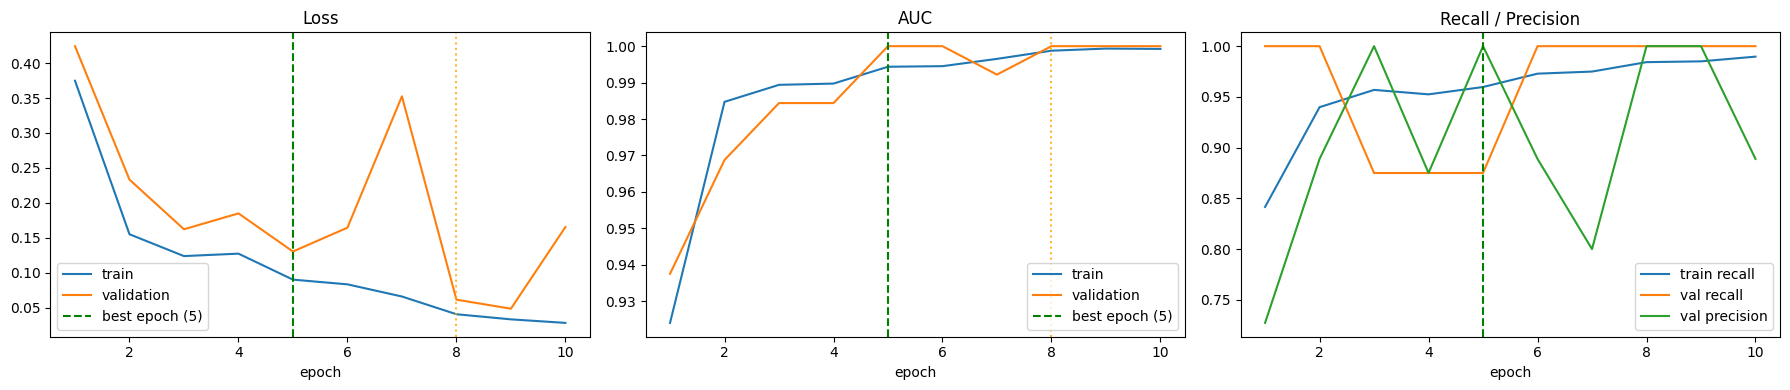

Stopped at epoch: 10 | best epoch: 5
LR reduced at epochs: [8]
Final gap  loss: 0.137 | auc: -0.001


In [ ]:
h = history.history
epochs = range(1, len(h["loss"]) + 1)
best_epoch = int(np.argmax(h["val_auc"])) + 1


lr = h["learning_rate"]
lr_drops = [i + 1 for i in range(1, len(lr)) if lr[i] < lr[i - 1]]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, (metric, title) in zip(axes[:2], [("loss", "Loss"), ("auc", "AUC")]):
    ax.plot(epochs, h[metric], label="train")
    ax.plot(epochs, h[f"val_{metric}"], label="validation")
    ax.axvline(best_epoch, color="green", ls="--", label=f"best epoch ({best_epoch})")
    for e in lr_drops:
        ax.axvline(e, color="orange", ls=":", alpha=0.8)
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()

axes[2].plot(epochs, h["recall"], label="train recall")
axes[2].plot(epochs, h["val_recall"], label="val recall")
axes[2].plot(epochs, h["val_precision"], label="val precision")
axes[2].axvline(best_epoch, color="green", ls="--")
axes[2].set_title("Recall / Precision"); axes[2].set_xlabel("epoch"); axes[2].legend()

plt.tight_layout(); plt.show()

print("Stopped at epoch:", len(epochs), "| best epoch:", best_epoch)
print("LR reduced at epochs:", lr_drops)
print(f"Final gap  loss: {h['val_loss'][-1] - h['loss'][-1]:.3f} | "
      f"auc: {h['auc'][-1] - h['val_auc'][-1]:.3f}")

In [ ]:
X_test = np.stack(scaled_testing_images['image'].to_list()).astype("float32")
y_test = scaled_testing_images['label'].to_numpy().astype("int")


{'Accuracy': 0.7932692307692307, 'Precision': 0.7604790419161677, 'Recall': 0.9769230769230769, 'F1': 0.8552188552188552, 'ROC-AUC': np.float64(0.935842647381109)}
              precision    recall  f1-score   support

      NORMAL       0.93      0.49      0.64       234
   PNEUMONIA       0.76      0.98      0.86       390

    accuracy                           0.79       624
   macro avg       0.84      0.73      0.75       624
weighted avg       0.82      0.79      0.77       624



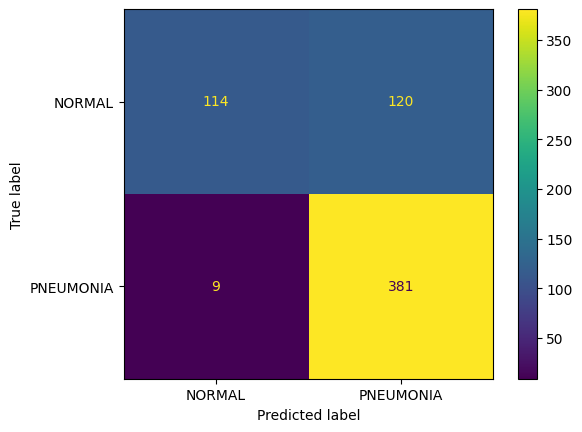

In [ ]:
THRESHOLD = 0.5

def evaluate(X, y, threshold=THRESHOLD):
    proba = model.predict(X, batch_size=64, verbose=0).ravel()
    pred = (proba >= threshold).astype(int)
    return {
        "Accuracy":  accuracy_score(y, pred),
        "Precision": precision_score(y, pred),
        "Recall":    recall_score(y, pred),
        "F1":        f1_score(y, pred),
        "ROC-AUC":   roc_auc_score(y, proba),
    }, proba, pred

test_metrics, test_proba, test_pred = evaluate(X_test, y_test)
print(test_metrics)
print(classification_report(y_test, test_pred, target_names=["NORMAL", "PNEUMONIA"]))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["NORMAL", "PNEUMONIA"]); plt.show()

In [ ]:
y_tr_int  = y_train.astype(int)       #
y_val_int = y_val.astype(int)

train_metrics, _, _ = evaluate(X_train, y_tr_int)
val_metrics, _, _   = evaluate(x_val, y_val_int)

results = pd.DataFrame({"Train": train_metrics,
                        "Validation": val_metrics,
                        "Test": test_metrics}).T.round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Train,0.973,0.998,0.965,0.982,0.999
Validation,0.938,1.000,0.875,0.933,1.000
Test,0.793,0.760,0.977,0.855,0.936


In [ ]:
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    p = (test_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append({"threshold": t,
                 "precision": precision_score(y_test, p, zero_division=0),
                 "recall": recall_score(y_test, p),
                 "specificity": tn / (tn + fp),
                 "FN (missed pneumonia)": fn,
                 "FP (false alarms)": fp})
pd.DataFrame(rows).round(3)

,threshold,precision,recall,specificity,FN (missed pneumonia),FP (false alarms)
0,0.1,0.687,0.995,0.244,2,177
1,0.2,0.700,0.995,0.291,2,166
2,0.3,0.715,0.995,0.338,2,155
3,0.4,0.733,0.992,0.397,3,141
4,0.5,0.760,0.977,0.487,9,120
5,0.6,0.790,0.972,0.568,11,101
6,0.7,0.813,0.956,0.632,17,86
7,0.8,0.858,0.944,0.739,22,61
8,0.9,0.888,0.918,0.808,32,45


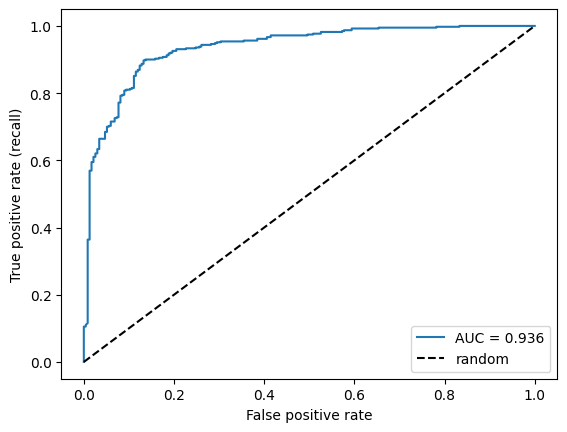

In [ ]:
fpr, tpr, _ = roc_curve(y_test, test_proba)
plt.plot(fpr, tpr, label=f"AUC = {test_metrics['ROC-AUC']:.3f}")
plt.plot([0, 1], [0, 1], "k--", label="random")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.legend(); plt.show()

In [ ]:
class_names = ["NORMAL", "PNEUMONIA"]

correct = np.where(test_pred == y_test)[0]
fp_idx = np.where((test_pred == 1) & (y_test == 0))[0]
fn_idx = np.where((test_pred == 0) & (y_test == 1))[0]

print(f"Correct: {len(correct)} | FP: {len(fp_idx)} | FN: {len(fn_idx)}")

Correct: 495 | FP: 120 | FN: 9


In [ ]:
def show_grid(indices, title, n=12, cols=4, seed=42):
    rng = np.random.default_rng(seed)
    if len(indices) == 0:
        print(f"No images for: {title}")
        return
    chosen = rng.choice(indices, size=min(n, len(indices)), replace=False)
    rows = int(np.ceil(len(chosen) / cols))
    plt.figure(figsize=(cols * 3.2, rows * 3.4))
    for k, i in enumerate(chosen):
        plt.subplot(rows, cols, k + 1)
        plt.imshow(X_test[i])
        plt.axis("off")
        plt.title(f"true: {class_names[int(y_test[i])]}\n"
                  f"score: {test_proba[i]:.2f}", fontsize=9,
                  color="green" if test_pred[i] == y_test[i] else "red")
    plt.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

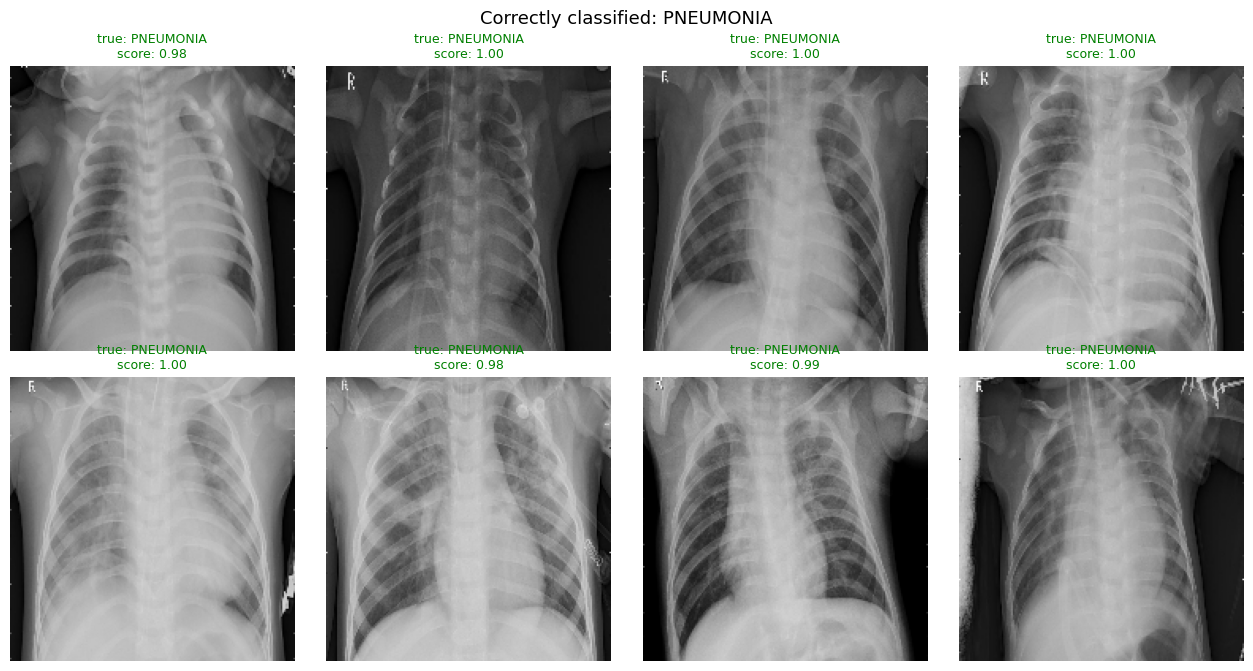

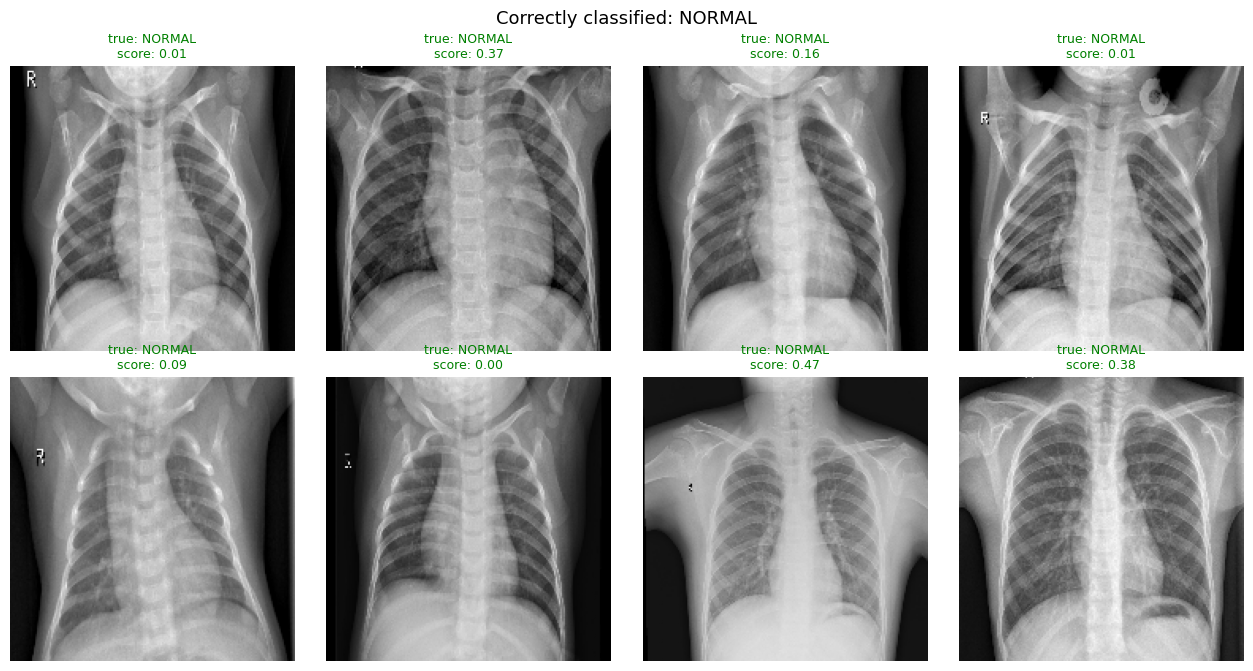

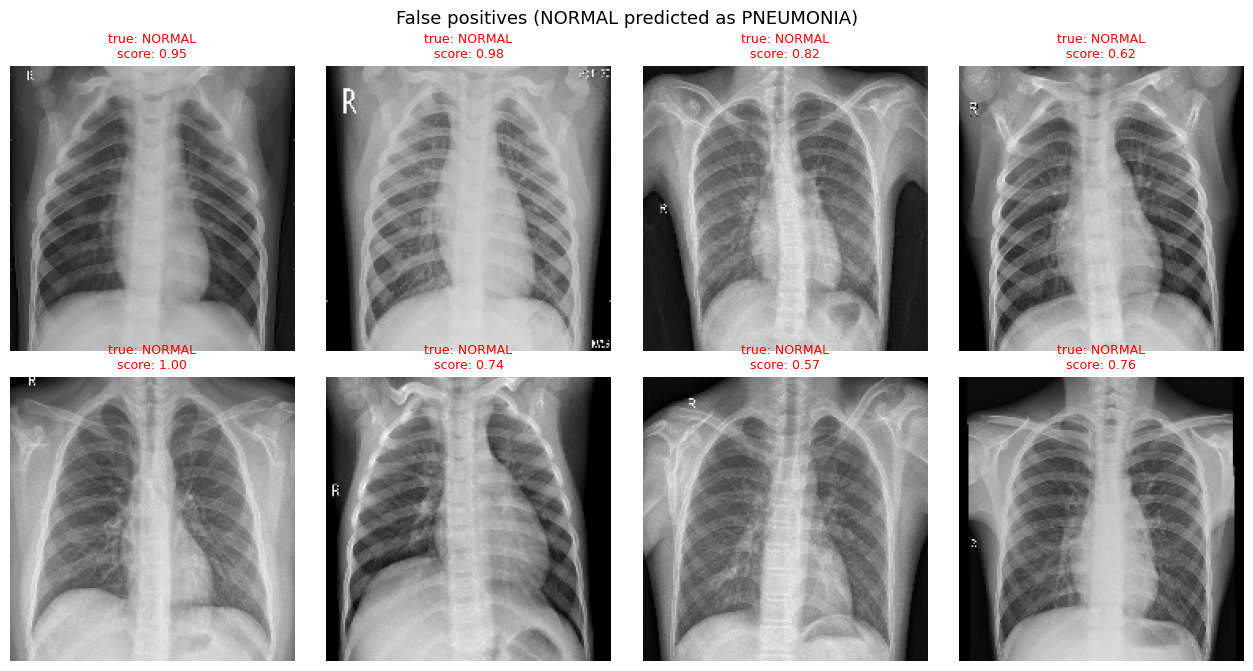

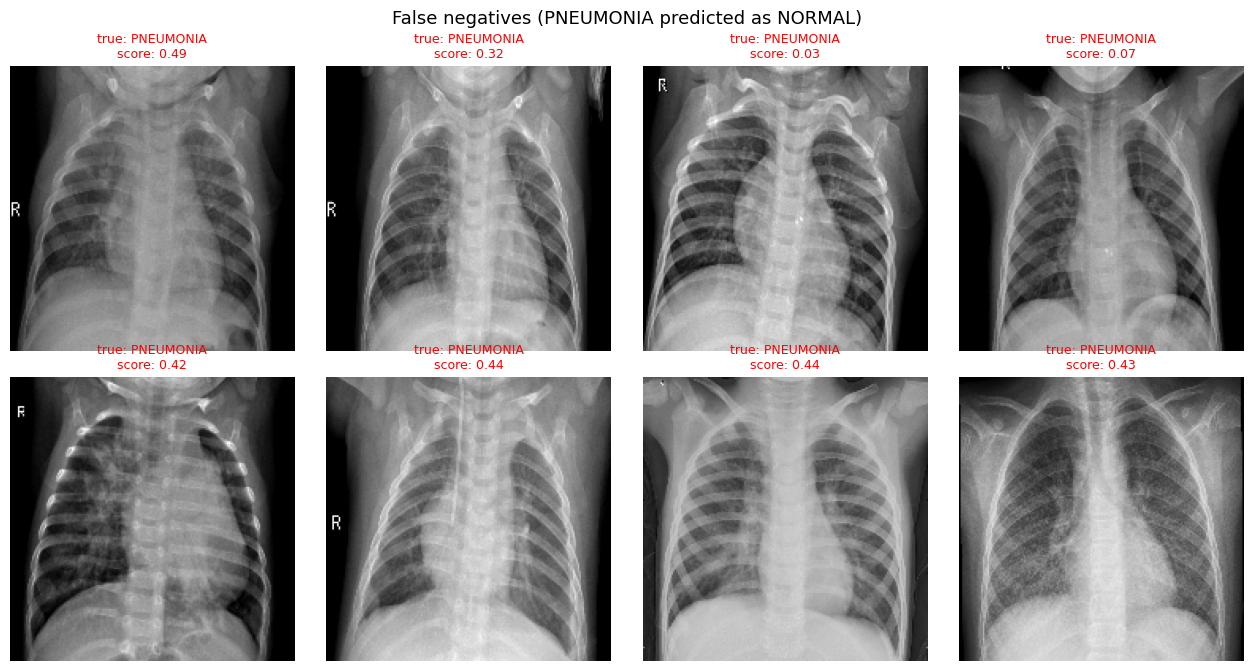

In [ ]:

show_grid(correct[y_test[correct] == 1], "Correctly classified: PNEUMONIA", n=8)
show_grid(correct[y_test[correct] == 0], "Correctly classified: NORMAL", n=8)


show_grid(fp_idx, "False positives (NORMAL predicted as PNEUMONIA)", n=8)
show_grid(fn_idx, "False negatives (PNEUMONIA predicted as NORMAL)", n=8)

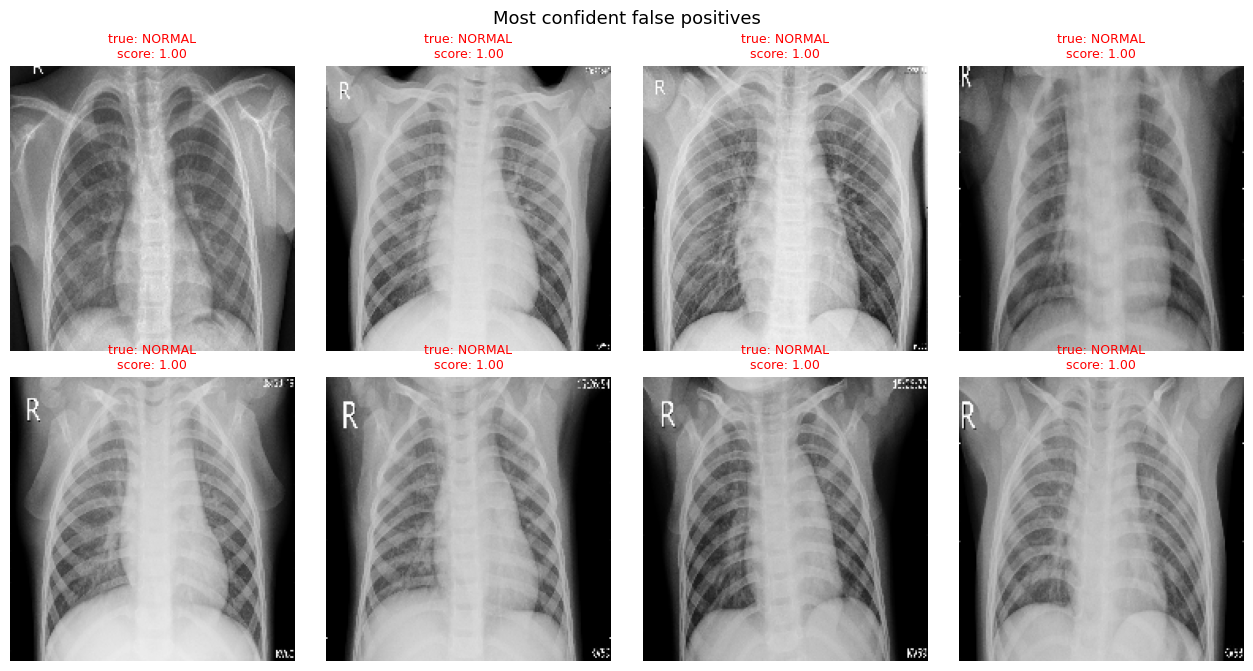

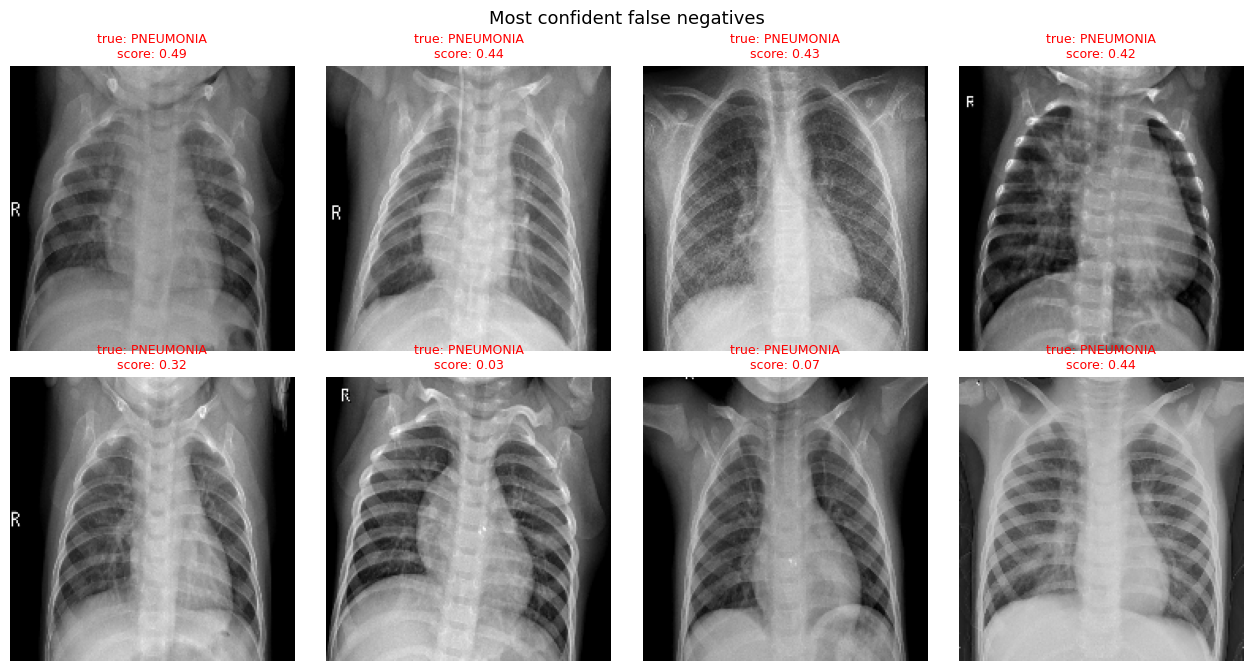

In [ ]:
worst_fp = fp_idx[np.argsort(-test_proba[fp_idx])][:8]
worst_fn = fn_idx[np.argsort(test_proba[fn_idx])][:8]
show_grid(worst_fp, "Most confident false positives", n=8)
show_grid(worst_fn, "Most confident false negatives", n=8)

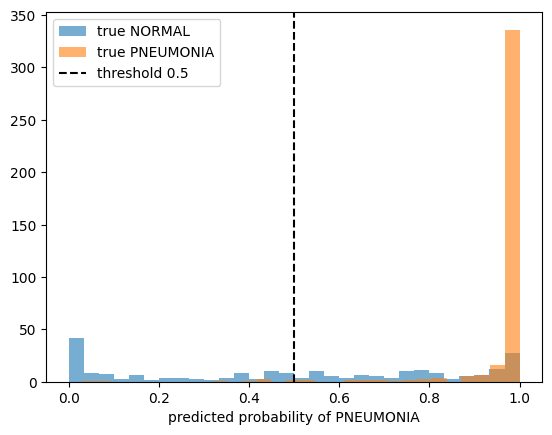

In [ ]:
def stats(idx):
    imgs = X_test[idx]
    return {"n": len(idx),
            "mean brightness": imgs.mean(),
            "contrast (std)": imgs.std(axis=(1, 2, 3)).mean()}

pattern_df = pd.DataFrame({
    "Correct": stats(correct),
    "False positives": stats(fp_idx),
    "False negatives": stats(fn_idx),
}).T.round(3)
pattern_df

# Score distribution by outcome
plt.hist(test_proba[y_test == 0], bins=30, alpha=0.6, label="true NORMAL")
plt.hist(test_proba[y_test == 1], bins=30, alpha=0.6, label="true PNEUMONIA")
plt.axvline(THRESHOLD, color="k", ls="--", label=f"threshold {THRESHOLD}")
plt.xlabel("predicted probability of PNEUMONIA"); plt.legend(); plt.show()

# Transfer learninig

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow import data as tf_sdata

In [ ]:
resize_fn = keras.layers.Resizing(180,180)

In [ ]:
augmentation_layers = {
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1)
}

def data_augmentation(x):
  for layers in augmentation_layers:
    x = layers(x)
  return x

In [ ]:
base_model = MobileNetV2(
    input_shape=(180, 180, 3),
    weights="imagenet",
    include_top=False
)
base_model.trainable = False

#  for layer in base_model.layers:
#    print(layer)

IndentationError: unexpected indent (451643794.py, line 8)

In [ ]:
inputs = keras.Input(shape=(180, 180, 3))
scale_layer = keras.layers.Rescaling(scale=1 / 127.5, offset=-1)
x = scale_layer(inputs)
x = base_model(inputs, training=False)

In [ ]:
x = keras.layers.GlobalAveragePooling2D()(x)

In [ ]:
x = layers.Dropout(0.2)(x)

In [ ]:
outputs = keras.layers.Dense(1)(x)
model = keras.Model(inputs, outputs)

In [ ]:
model.compile(
    optimizer= keras.optimizers.Adam(),
    loss= keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy", "precision", "recall", "auc"]
)


In [ ]:
epochs = 5
print("Fitting the top layer of the model")
ransfer_learning_history = model.fit(
    X_train, y_train,
    epochs=epochs,
    class_weight=class_weights,
    validation_data=(x_val, y_val),
    callbacks=[early_stop, reduce_lr]
    )

Fitting the top layer of the model
Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 27s 101ms/step - accuracy: 0.8313 - auc: 0.9008 - loss: 0.2941 - precision: 0.9728 - recall: 0.7951 - val_accuracy: 0.8750 - val_auc: 0.9141 - val_loss: 0.2547 - val_precision: 1.0000 - val_recall: 0.7500 - learning_rate: 0.0010
Epoch 2/5
162/163 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9154 - auc: 0.9508 - loss: 0.1649 - precision: 0.9878 - recall: 0.8961
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
163/163 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9174 - auc: 0.9516 - loss: 0.1659 - precision: 0.9892 - recall: 0.8986 - val_accuracy: 0.8750 - val_auc: 0.9375 - val_loss: 0.1994 - val_precision: 1.0000 - val_recall: 0.7500 - learning_rate: 0.0010
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9262 - auc: 0.9592 - loss: 0.1428 - precision: 0.9899 - recall: 0.9099 - val_accuracy: 0.8750 - val_auc: 1.0000 - val_loss: 0.1829 - val_precision: 1.0000 - val_r

# Fine tunning

In [ ]:
len(base_model.layers)

154

In [ ]:
base_model.trainable = True
for layer in base_model.layers[:90]:
  layer.trainable = False

model.compile(
    optimizer= keras.optimizers.Adam(0.00001),
    loss= keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy", "precision", "recall", "auc"]
)


In [ ]:
fine_tuned_history = model.fit(
    X_train, y_train,
    epochs=epochs,
    class_weight=class_weights,
    validation_data=(x_val, y_val),
    callbacks=[early_stop, reduce_lr]
    )

Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 26s 59ms/step - accuracy: 0.9385 - auc: 0.9610 - loss: 0.1357 - precision: 0.9879 - recall: 0.9285 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0531 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - accuracy: 0.9651 - auc: 0.9787 - loss: 0.0735 - precision: 0.9949 - recall: 0.9579 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0256 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step - accuracy: 0.9734 - auc: 0.9833 - loss: 0.0558 - precision: 0.9960 - recall: 0.9680 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0509 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step - accuracy: 0.9816 - auc: 0.9883 - loss: 0.0426 - precision: 0.9974 - recall: 0.9778 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss:

In [ ]:
transfer_learning_history = ransfer_learning_history.history
fine_tuned_history = fine_tuned_history.history

In [ ]:
transfer_learning_history

{'accuracy': [0.8312883377075195,
  0.9173696041107178,
  0.9261886477470398,
  0.9342408180236816,
  0.9361580014228821],
 'auc': [0.9007514119148254,
  0.9516198039054871,
  0.9591518044471741,
  0.9603650569915771,
  0.964762806892395],
 'loss': [0.294082909822464,
  0.1658746600151062,
  0.14281468093395233,
  0.13256163895130157,
  0.11971812695264816],
 'precision': [0.9728449583053589,
  0.9892045259475708,
  0.9898933172225952,
  0.9913744926452637,
  0.9927657246589661],
 'recall': [0.795096755027771,
  0.8985806703567505,
  0.909935474395752,
  0.9194839000701904,
  0.9207742214202881],
 'val_accuracy': [0.875, 0.875, 0.875, 0.875, 0.875],
 'val_auc': [0.9140625, 0.9375, 1.0, 1.0, 1.0],
 'val_loss': [0.25473737716674805,
  0.1993986964225769,
  0.18292959034442902,
  0.16961681842803955,
  0.16496866941452026],
 'val_precision': [1.0, 1.0, 1.0, 1.0, 1.0],
 'val_recall': [0.75, 0.75, 0.75, 0.75, 0.75],
 'learning_rate': [0.0010000000474974513,
  0.0010000000474974513,
  0.0005

In [ ]:
base_model.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 180, 180,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 90, 90,    │        864 │ input_layer_3[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 90, 90,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 90, 90,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 90, 90,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 90, 90,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 90, 90,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 90, 90,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 90, 90,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 90, 90,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 90, 90,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 90, 90,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 91, 91,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 45, 45,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 45, 45,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 45, 45,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 45, 45,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 1,959,808 (7.48 MB)

 Non-trainable params: 298,176 (1.14 MB)